In [1]:
import pandas as pd 
import numpy as np                  
import matplotlib.pyplot as plt           
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf  
from statsmodels.tsa.arima_model import ARIMA       
import statsmodels.api as sm                        
import statsmodels.tsa.api as smtsa    

In [2]:
import yfinance as yf

ticker_symbol = "PFE"


data = yf.download(ticker_symbol, period="10y")  

data.to_csv('Pfizer Inc.csv')

[*********************100%***********************]  1 of 1 completed


In [3]:
# plotds is method to plot time series, ACF and PACF
def plotds(xt, nlag = 30, fig_size = (10, 8)):            # Function to plot time series, ACF, and PACF
    if not isinstance(xt, pd.Series):                      # Check if input is not a pandas Series
         xt = pd.Series(xt)                                # Convert input to pandas Series if needed
         
    plt.figure(figsize = fig_size)                         
    layout = (2, 2)                                        
    
    ax_xt = plt.subplot2grid(layout, (0, 0), colspan = 2)  # Top plot spans both columns (time series)
    ax_acf= plt.subplot2grid(layout, (1, 0))               # Bottom-left plot for ACF
    ax_pacf = plt.subplot2grid(layout, (1, 1))             # Bottom-right plot for PACF
    
    xt.plot(ax = ax_xt)                                  
    ax_xt.set_title('Time Series')                         
    
    plot_acf(xt, lags = 50, ax = ax_acf)                   
    plot_pacf(xt, lags = 50, ax = ax_pacf)                 
    
    plt.tight_layout()                                     # Adjust layout to prevent overlapping
    return None                                            # Function returns nothing

In [4]:
df_Pfizer= pd.read_csv("Pfizer Inc.csv",skiprows=[0,1],index_col=0, parse_dates=True )

In [48]:
df_Pfizer.shape

(2513, 5)

In [6]:
df_Pfizer.head()

,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
Date,,,,,
2016-10-20,19.600229,19.720697,19.570111,19.570111,20334190
2016-10-21,19.383383,19.546015,19.383383,19.527944,19852090
2016-10-24,19.353266,19.491804,19.305079,19.455663,20644066
2016-10-25,19.443623,19.497833,19.268943,19.287013,20380249
2016-10-26,19.515898,19.636366,19.365312,19.443617,18026246


In [7]:
data=df_Pfizer.rename(columns={"Unnamed: 1": "Close",
                         "Unnamed: 2": "High",
                         "Unnamed: 3": "Low",
                         "Unnamed: 4": "Open",
                         "Unnamed: 5": "Volume"})


In [8]:
data.isnull().sum()

Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

In [9]:
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2513 entries, 2016-10-20 to 2026-10-20
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   2513 non-null   float64
 1   High    2513 non-null   float64
 2   Low     2513 non-null   float64
 3   Open    2513 non-null   float64
 4   Volume  2513 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 117.8 KB


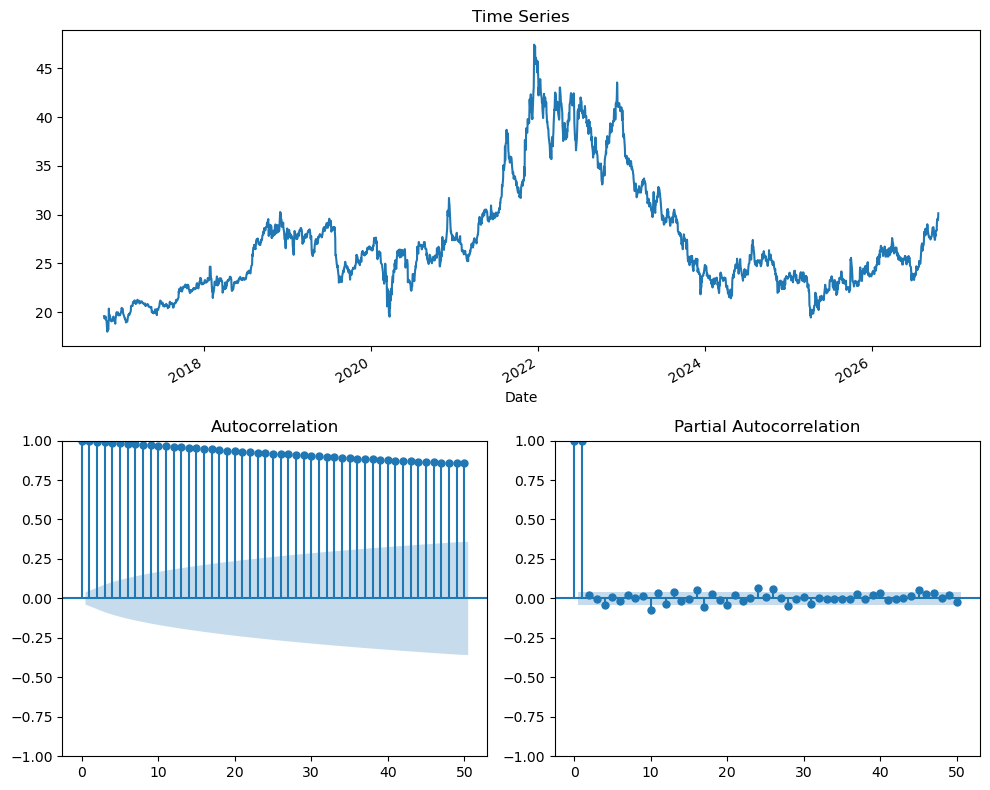

In [10]:
plotds(data['Close'], nlag = 100)

In [11]:
mean1, mean2 = data.iloc[:125].Close.mean(), data.iloc[125:].Close.mean()

var1, var2 = data.iloc[:125].Close.var(), data.iloc[125:].Close.var()

print('mean1 = %f, mean2 = %f' % (mean1, mean2))
print('variance1 = %f, variance2 = %f' % (var1, var2))

mean1 = 20.016284, mean2 = 27.560573
variance1 = 0.683802, variance2 = 31.780544


In [12]:
from statsmodels.tsa.stattools import adfuller

# Call adfuller() function to calculate the values
adf = adfuller(data.Close.tolist())
print('ADF Statistic: %f' % adf[0])
print('p-value: %f' % adf[1])

ADF Statistic: -2.026309
p-value: 0.275158


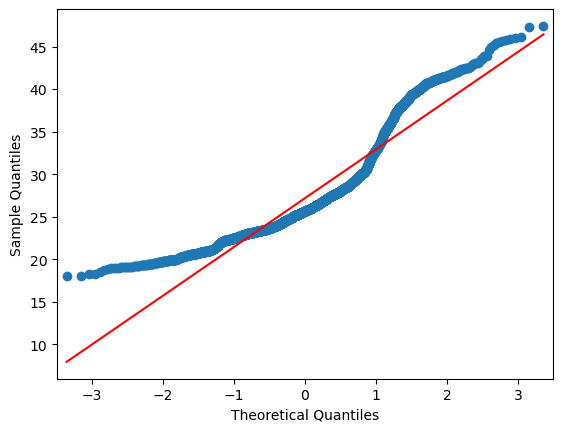

In [13]:
# qqplot for the 'Close' column
x = sm.qqplot(data['Close'], line = 's')

In [14]:
from statsmodels.tsa.arima.model import ARIMA

# Call ARIMA function to train the model on the 'Close' price
model = ARIMA(data['Close'], order = (1, 1, 0))

# Train ARIMA Model on the 'Close' price dataset
results_AR = model.fit()

/Users/erdene-undrakh/anaconda3/envs/python-3-14/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/erdene-undrakh/anaconda3/envs/python-3-14/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/erdene-undrakh/anaconda3/envs/python-3-14/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


In [15]:
# Store one difference value of the 'Close' column
first_order_diff = data['Close'].diff(1)

# Display the first five records
first_order_diff.head()

Date
2016-10-20         NaN
2016-10-21   -0.216846
2016-10-24   -0.030117
2016-10-25    0.090357
2016-10-26    0.072275
Name: Close, dtype: float64

In [16]:
# Drop the first row of 'Close' column because It has 'NaN' value
first_order_diff = data['Close'].diff(1).dropna()

# Display the first five records
first_order_diff.head()

Date
2016-10-21   -0.216846
2016-10-24   -0.030117
2016-10-25    0.090357
2016-10-26    0.072275
2016-10-27    0.048185
Name: Close, dtype: float64

Text(0.5, 1.0, 'First-order differences of Pfizer during Jan 2016-Dec 2016')

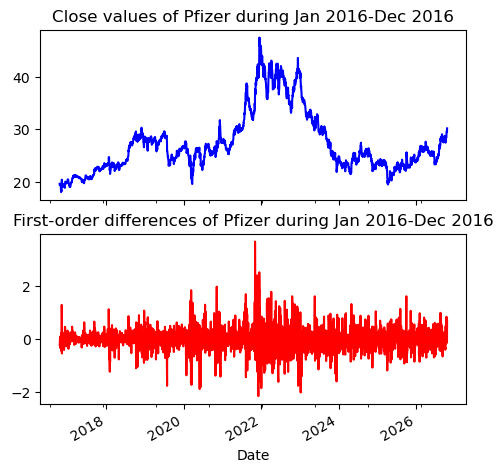

In [17]:
# Declare the fig abd ax as two arguments 
fig, ax = plt.subplots(2, sharex = True)
fig.set_size_inches(5.5, 5.5)
data['Close'].plot(ax = ax[0], color = 'b')
ax[0].set_title('Close values of Pfizer during Jan 2016-Dec 2016')
first_order_diff.plot(ax = ax[1], color = 'r')
ax[1].set_title('First-order differences of Pfizer during Jan 2016-Dec 2016')

ADF Statistic: -10.212801
p-value: 0.000000


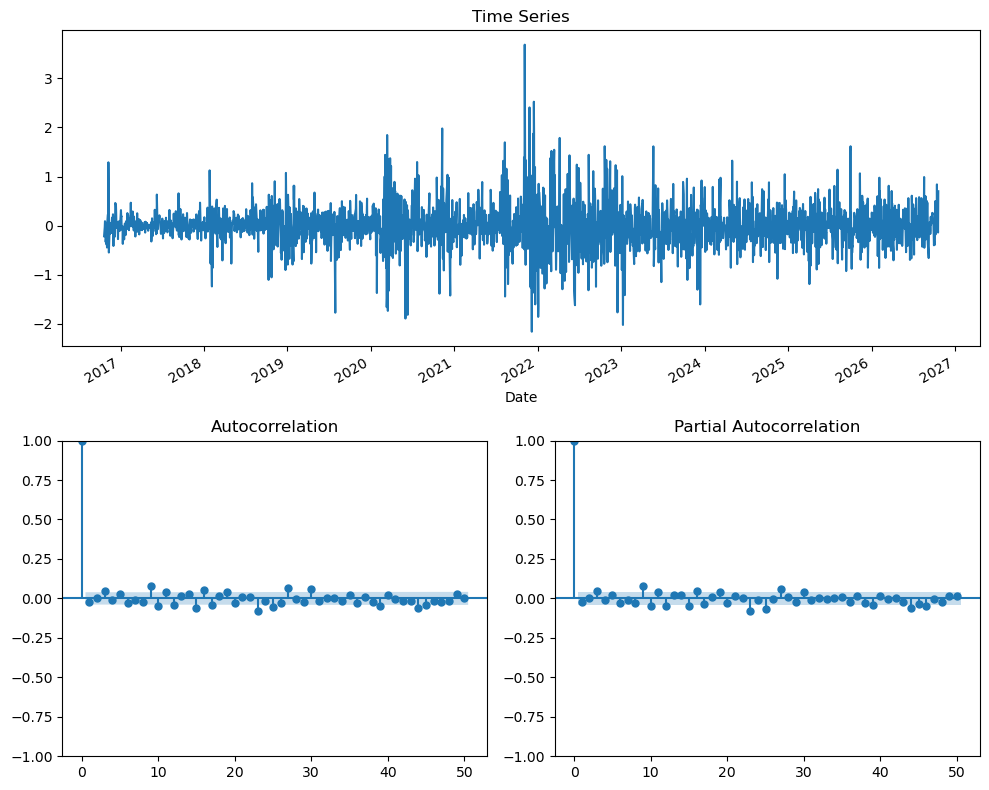

In [18]:
# data with 50 lags
plotds(first_order_diff, nlag = 50)

# Dicky Fuller test
adf_result = adfuller(first_order_diff)

print('ADF Statistic: %f' % adf_result[0])
print('p-value: %f' % adf_result[1])

In [19]:
# A nested loop is written to calculate the AIC values
aicVal = []                                      # Initialize an empty list to store ARIMA parameters and AIC values

for d in range(1, 3):                             # Loop over differencing order (d = 1 to 2)
    for ari in range(0, 3):                       # Loop over AR terms (p = 0 to 2)
        for maj in range(0, 3):                   # Loop over MA terms (q = 0 to 2)
            try:
                arima_obj = ARIMA(data['Close'].tolist(), order=(ari, d, maj))  # Create ARIMA model with parameters (p=ari, d=d, q=maj)                
                arima_obj_fit = arima_obj.fit()                                    # Fit the ARIMA model to the data                
                aicVal.append([ari, d, maj, float(arima_obj_fit.aic)])             # Store p, d, q values along with the computed AIC
            except ValueError:                                                     # Handle cases where model fails to fit
                pass                                                               # Ignore errors and continue loop

# Print results line by line
for val in aicVal:                                                                 # Loop through stored AIC results
    print(val)                                                                     

/Users/erdene-undrakh/anaconda3/envs/python-3-14/lib/python3.14/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/erdene-undrakh/anaconda3/envs/python-3-14/lib/python3.14/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


[0, 1, 0, 2947.6234277005706]
[0, 1, 1, 2948.317717467697]
[0, 1, 2, 2950.218616776735]
[1, 1, 0, 2948.304824804636]
[1, 1, 1, 2950.297962465227]
[1, 1, 2, 2942.156278906889]
[2, 1, 0, 2950.270915008018]
[2, 1, 1, 2951.0933556048058]
[2, 1, 2, 2922.659896750296]
[0, 2, 0, 4743.404617003587]
[0, 2, 1, 2957.0467432631967]
[0, 2, 2, 2957.775773979659]
[1, 2, 0, 3978.598122401134]
[1, 2, 1, 2957.8173877047393]
[1, 2, 2, 2955.150310710595]
[2, 2, 0, 3619.5692880687475]
[2, 2, 1, 2959.722662120903]
[2, 2, 2, 2951.0780509432398]


/Users/erdene-undrakh/anaconda3/envs/python-3-14/lib/python3.14/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [20]:
best_model = min(aicVal, key=lambda x: x[3])
print(f"\nMinimum AIC value: {best_model[3]:.2f}")
print(f"Best model: ARIMA({best_model[0]}, {best_model[1]}, {best_model[2]})")


Minimum AIC value: 2922.66
Best model: ARIMA(2, 1, 2)


In [21]:
# Declare and initialise an object 'arima_obj' by calling a method 'ARIMA()'
arima_obj = ARIMA(data['Close'].tolist(), order = (2, 1, 2))

#d = 1, the number of times that the raw observations are differenced, also called the degree of differencing.

arima_obj_fit = arima_obj.fit()


arima_obj_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                 2513
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -1456.330
Date:                Tue, 20 Oct 2026   AIC                           2922.660
Time:                        20:56:01   BIC                           2951.804
Sample:                             0   HQIC                          2933.238
                               - 2513                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -1.3634      0.007   -204.768      0.000      -1.376      -1.350
ar.L2         -0.9830      0.007   -148.280      0.000      -0.996      -0.970
ma.L1          1.3522      0.010    140.927      0.000       1.333       1.371
ma.L2          0.9626      0.010     98.109      0.000       0.943       0.982
sigma2         0.1866      0.003     64.710      0.000       0.181       0.192
===================================================================================
Ljung-Box (L1) (Q):                   0.02   Jarque-Bera (JB):              2852.63
Prob(Q):                              0.88   Prob(JB):                         0.00
Heteroskedasticity (H):               1.69   Skew:                             0.29
Prob(H) (two-sided):                  0.00   Kurtosis:                         8.19
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [22]:
pred = arima_obj_fit.fittedvalues

data['ARIMA'] = pred      

diffval = arima_obj_fit.resid + arima_obj_fit.fittedvalues

data['diffval'] = diffval

# 'ARIMA', 'Residues and fitted' and 'diffval' values are added and stored into dataframe, 

# Display first five records
data.head()

,Close,High,Low,Open,Volume,ARIMA,diffval
Date,,,,,,,
2016-10-20,19.600229,19.720697,19.570111,19.570111,20334190,0.000000,19.600229
2016-10-21,19.383383,19.546015,19.383383,19.527944,19852090,19.600229,19.383383
2016-10-24,19.353266,19.491804,19.305079,19.455663,20644066,19.387634,19.353266
2016-10-25,19.443623,19.497833,19.268943,19.287013,20380249,19.355204,19.443623
2016-10-26,19.515898,19.636366,19.365312,19.443617,18026246,19.436178,19.515898


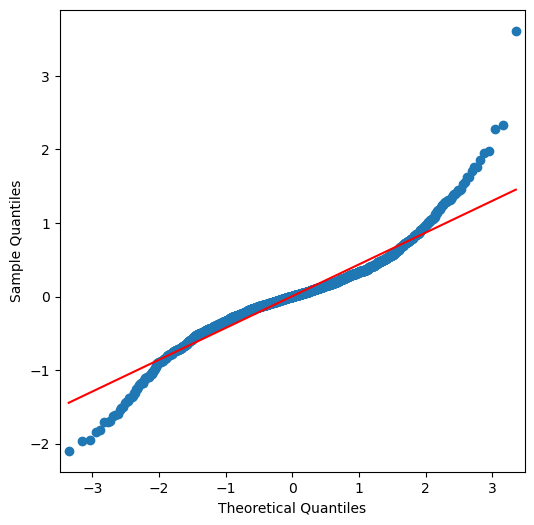

In [23]:
fig, ax = plt.subplots(figsize=(6, 6))
residuals = arima_obj_fit.resid[2:]

sm.qqplot(residuals, line='s', ax=ax)
plt.show()

In [24]:
print(data['diffval'], data['ARIMA'])

Date
2016-10-20    19.600229
2016-10-21    19.383383
2016-10-24    19.353266
2016-10-25    19.443623
2016-10-26    19.515898
                ...    
2026-10-14    29.209999
2026-10-15    29.440001
2026-10-16    29.580000
2026-10-19    29.440001
2026-10-20    30.141001
Name: diffval, Length: 2513, dtype: float64 Date
2016-10-20     0.000000
2016-10-21    19.600229
2016-10-24    19.387634
2016-10-25    19.355204
2016-10-26    19.436178
                ...    
2026-10-14    28.381579
2026-10-15    29.202650
2026-10-16    29.419092
2026-10-19    29.609092
2026-10-20    29.419499
Name: ARIMA, Length: 2513, dtype: float64


In [25]:
data['diffval'].iloc[2:]
# Ignoring first two rows because of difference factor d = 2

Date
2016-10-24    19.353266
2016-10-25    19.443623
2016-10-26    19.515898
2016-10-27    19.564083
2016-10-28    19.232800
                ...    
2026-10-14    29.209999
2026-10-15    29.440001
2026-10-16    29.580000
2026-10-19    29.440001
2026-10-20    30.141001
Name: diffval, Length: 2511, dtype: float64

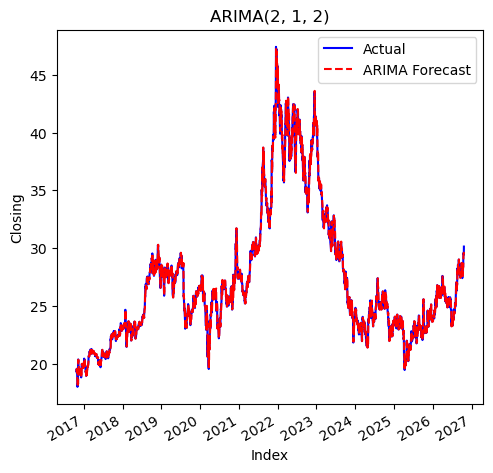

In [26]:
f, axarr = plt.subplots(1, sharex=True)
f.set_size_inches(5.5, 5.5)


data['diffval'].iloc[2:].plot(color='b', linestyle='-', ax=axarr, label='Actual')
data['ARIMA'].iloc[2:].plot(color='r', linestyle='--', ax=axarr, label='ARIMA Forecast')
axarr.set_title('ARIMA(2, 1, 2)')
axarr.set_xlabel('Index')
axarr.set_ylabel('Closing')
axarr.legend()  # Add legend

plt.show()

In [27]:
from sklearn.metrics import r2_score

actual = data['diffval'].iloc[2:]
predicted = data['ARIMA'].iloc[2:]

# Ensure same length (important!)
actual, predicted = actual.align(predicted, join='inner')

r2 = r2_score(actual, predicted)
print(f"R² Score: {r2:.4f}")

R² Score: 0.9943


In [28]:
result = arima_obj_fit.get_forecast()
forecast = result.predicted_mean
intervals = [0.2, 0.1, 0.05, 0.01]

for i in range(len(forecast)):
    for a in intervals:
        ci = result.conf_int(alpha=a)
        
        lower = ci[i, 0]
        upper = ci[i, 1]
        
        print(f"Step {i+1} - {(1-a)*100:.1f}% CI: {forecast[i]:.3f} between {lower:.3f} and {upper:.3f}")

Step 1 - 80.0% CI: 30.136 between 29.582 and 30.689
Step 1 - 90.0% CI: 30.136 between 29.425 and 30.846
Step 1 - 95.0% CI: 30.136 between 29.289 and 30.982
Step 1 - 99.0% CI: 30.136 between 29.023 and 31.249


In [29]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [43]:
closing_prices = data["Close"].values

model = sm.tsa.ARIMA(closing_prices, order = (0, 2, 1))
arima_obj_fit = model.fit()

# Forecast next 20 points
steps    = 120
result   = arima_obj_fit.get_forecast(steps=steps)
forecast = result.predicted_mean

In [44]:
# Time indices 
time_steps   = np.arange(len(closing_prices))
future_steps = np.arange(len(closing_prices), len(closing_prices) + steps)

In [45]:
# Get confidence intervals
ci_80 = result.conf_int(alpha = 0.20)   
ci_95 = result.conf_int(alpha = 0.05)   

lower_80, upper_80 = ci_80[:, 0], ci_80[:, 1]
lower_95, upper_95 = ci_95[:, 0], ci_95[:, 1]

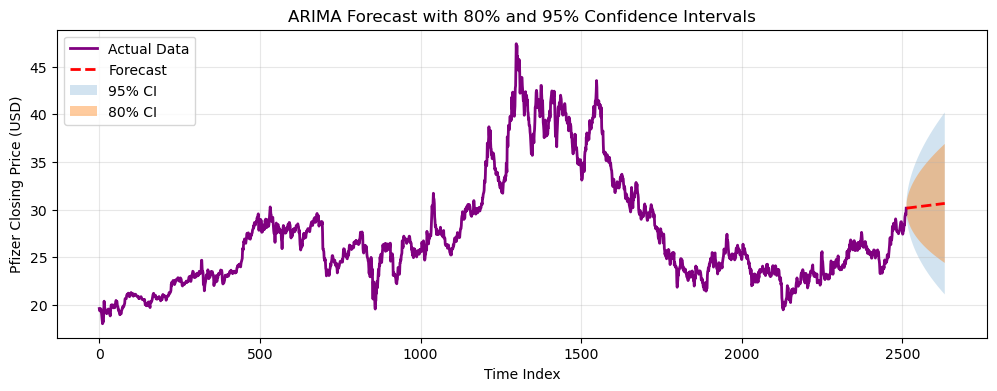

In [46]:
plt.figure(figsize = (12, 4))

plt.plot(time_steps, closing_prices, color = "purple", linewidth = 2, label = "Actual Data")

plt.plot(future_steps, forecast, color = "red", linestyle = "--", linewidth = 2, label = "Forecast")

# Confidence intervals
plt.fill_between(future_steps, lower_95, upper_95, alpha = 0.2, label = "95% CI")
plt.fill_between(future_steps, lower_80, upper_80, alpha = 0.4, label = "80% CI")


plt.xlabel("Time Index")
plt.ylabel("Pfizer Closing Price (USD)")
plt.title("ARIMA Forecast with 80% and 95% Confidence Intervals")
plt.legend()
plt.grid(True, alpha = 0.3)
plt.show()

# References 
- Tutorial 6 (a), ARIMA model, Time-Series Analysis, Muhammad Iqbal, 2026
- Lecture 6, Time-Series Model, Muhammad Iqbal, 2026
- Tutorial 5, Time-Series Model, Muhammad Iqbal, 2026 